# EDA — Malla Vial Integral de Bogotá D.C. y Puentes

Este cuaderno realiza el **Análisis Exploratorio de Datos (EDA)** de las dos capas geoespaciales base del proyecto:

1. **Malla Vial Integral de Bogotá D.C.** (`Malla_Vial_Integral_Bogota_D_C (3).geojson`) — red vial (líneas), unidad espacial base del proyecto.
2. **Puentes** (`Puente.gpkg`) — infraestructura de puentes peatonales/vehiculares (polígonos).

El cuaderno está organizado así:

1. Diccionario de variables (Malla Vial y Puentes)
2. Carga de librerías y datos
3. EDA — Malla Vial Integral
4. EDA — Puentes
5. Resumen y hallazgos clave


## 1. Diccionario de variables

> Los nombres de columnas provienen directamente de los metadatos oficiales del IDECA / Catastro Bogotá. Cuando el significado exacto de un código no está documentado en la fuente, se indica como *"código interno / sin documentación oficial"* y se infiere su naturaleza a partir de los valores observados en los datos.

### 1.1 Malla Vial Integral de Bogotá D.C. (`malla`)

43 columnas, 136.957 registros (segmentos viales).

| Variable | Tipo | Descripción |
|---|---|---|
| `OBJECTID` | int | Identificador único interno del registro (ArcGIS). |
| `MVICCALZAD` | float | Código de la calzada asociada al segmento vial. |
| `MVICCAT` | str/object | Código catastral (CHIP/manzana) de referencia del segmento. |
| `MVITIPO` | str | Tipo de vía según nomenclatura oficial de Bogotá: `CL` (Calle), `KR` (Carrera), `AC` (Avenida Calle), `AK` (Avenida Carrera), `DG` (Diagonal), `TV` (Transversal). |
| `MVINOMBRE` | str | Nombre/nomenclatura del segmento vial (ej. `8A -57`). |
| `MVINALTERN` | str | Nombre alterno o coloquial de la vía (ej. `AUTOPISTA NORTE`, `AVENIDA EL DORADO`). |
| `MVINPRINCI` | str | Código de la vía principal a la que pertenece el segmento. |
| `MVINGENERA` | str | Código de la vía generadora (vía de referencia para la nomenclatura). |
| `MVINANTIGU` | str | Nomenclatura vial antigua/histórica del segmento. |
| `MVIETIQUET` | str | Etiqueta de nomenclatura vial completa. |
| `MVISVIA` | str | Estado de la vía: `B` (Bueno), `SD` (Sin Dato), `FT` (Fuera de Trazado?), `TF`, `N` (No existe/proyectada). |
| `MVICIV` | float | Código de la Cartografía / Identificador Vial (CIV) del segmento. |
| `MVINVIA` | int | Número de vía (correlativo). |
| `MVIEVIA` | str | Estado de ejecución de la vía: `M` (Malla vial existente), `B`, `R`, `SD` (sin dato). |
| `MVIFRIGHT` | float | Código del segmento adyacente en el costado derecho (from). |
| `MVITRIGHT` | float | Código del segmento adyacente en el costado derecho (to). |
| `MVIFLEFT` | float | Código del segmento adyacente en el costado izquierdo (from). |
| `MVITLEFT` | float | Código del segmento adyacente en el costado izquierdo (to). |
| `MVITM` | int | Indicador/código de Transmilenio asociado al segmento. |
| `MVICM` | int | Indicador/código de ciclorruta asociado al segmento. |
| `MVINUMC` | float | Número de calzadas del segmento vial. |
| `MVIACAL` | float | Ancho de calzada (m aprox.). |
| `MVIEFUN` | str | Estado funcional de la vía (`SD` = Sin Dato en la práctica totalidad de registros). |
| `MVITCONE` | str/int | Tipo de conexión del segmento en la topología de red (1 a 5; `5` = mayoría, tramo estándar). |
| `NAME` | str | Nombre general asociado al segmento (frecuentemente `BOGOTA`). |
| `MUNICIPIO` | str | Municipio (prácticamente 100% `BOGOTA`). |
| `PREFIJO` | str | Prefijo de orientación/zona de la nomenclatura vial (`S` = Sur, `E` = Este, `SE` = Sur-Este, vacío = sin prefijo/Norte-Centro). |
| `MVIVEL` | object | Columna sin datos (100% nulos/None) — reservada para velocidad, no poblada en esta fuente. |
| `MVIBICI` | object | Columna sin datos (100% nulos/None) — reservada para infraestructura ciclística, no poblada en esta fuente. |
| `MVIRCAR` | object | Columna sin datos (100% nulos/None) — reservada, no poblada en esta fuente. |
| `MVIESTV` | int | Constante en 0 en todo el dataset (columna no discriminante). |
| `MVITC` | int | Constante en 0 en todo el dataset (columna no discriminante). |
| `MVIRAPS` | int | Constante en 0 en todo el dataset (columna no discriminante). |
| `MVITSUP` | int | Tipo de superficie del pavimento (código 0–12; ver value_counts en el EDA). |
| `MVIMONIT` | int | Constante en 0 en todo el dataset (columna no discriminante). |
| `MVICODIGO` | int | Código único oficial del segmento vial (identificador de malla vial IDECA). |
| `CREADOR` | str | Usuario que creó el registro en el sistema (mayoritariamente nulo). |
| `CREADOR_DATE` | datetime | Fecha de creación del registro. |
| `EDITOR` | str | Usuario que editó por última vez el registro (`SIGADMIN` en casi todos los casos). |
| `EDITOR_DATE` | datetime | Fecha de la última edición del registro. |
| `MVI_VELREG` | float | Velocidad reglamentaria de la vía (km/h). |
| `Shape__Length` | float | Longitud de la geometría calculada por el sistema de origen. Se conserva tal cual venía en el archivo fuente (grados decimales, CRS original `EPSG:4326`); no se recalcula tras la reproyección. |
| `geometry` | geometry | Geometría del segmento vial: `LineString` o `MultiLineString`. Fuente original en `EPSG:4326` (WGS84); **estandarizada en este cuaderno a `EPSG:3116`** (MAGNA-SIRGAS / Bogotá, proyectado, unidades en metros). |

### 1.2 Puentes (`puentes`)

6 columnas, 1.212 registros.

| Variable | Tipo | Descripción |
|---|---|---|
| `PueCodigo` | int | Identificador único oficial del puente. |
| `PueTipo` | int | Tipo de puente (dominio IDECA). `1` = Vehicular (según el Catálogo de Objetos de IDECA). `2` = presumiblemente Peatonal, **pendiente de confirmar**: el catálogo consultado aparece truncado justo en ese valor y IDECA menciona además el ciclopuente como tipo de puente en Bogotá. Hasta tener confirmación escrita de IDECA/IDU, no se debe usar `PueTipo` como «peatonal» sin declarar el supuesto. |
| `PueUbicaci` | str | Descripción textual de la ubicación del puente (ej. intersección de vías o accidente geográfico que cruza). |
| `SHAPE_Length` | float | Perímetro de la geometría calculado por el sistema de origen. Se conserva tal cual venía en el archivo fuente (grados decimales, CRS original `EPSG:4686`); no se recalcula tras la reproyección. |
| `SHAPE_Area` | float | Área de la geometría calculada por el sistema de origen (grados decimales al cuadrado, CRS original `EPSG:4686`). |
| `geometry` | geometry | Geometría del puente: `MultiPolygon`. Fuente original en `EPSG:4686` (MAGNA-SIRGAS / Bogotá geográfico); **estandarizada en este cuaderno a `EPSG:3116`** (MAGNA-SIRGAS / Bogotá, proyectado, unidades en metros). |

### 1.3 Estandarización de CRS

Ambas capas llegan en sistemas de referencia distintos y no proyectados (`EPSG:4326` y `EPSG:4686`), lo cual impide calcular longitudes/áreas reales en metros y complica cualquier análisis espacial conjunto (uniones, distancias, buffers). Por eso, **al inicio de este cuaderno ambas capas se reproyectan a `EPSG:3116`** (MAGNA-SIRGAS / Colombia Bogotá zone), el sistema de referencia proyectado oficial recomendado para trabajo cartográfico de precisión en Bogotá D.C., con unidades en metros.


## 2. Carga de librerías y datos

In [3]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 60)
plt.rcParams['figure.figsize'] = (9, 6)


In [4]:
# Carga de las dos capas base
malla = gpd.read_file("Data/raw/Malla_Vial_Integral_Bogota_D_C (3).geojson")
puentes = gpd.read_file("Data/raw/Puentes bogota.gpkg")

print("Malla vial:", malla.shape, "| CRS original:", malla.crs)
print("Puentes   :", puentes.shape, "| CRS original:", puentes.crs)


Malla vial: (136957, 43) | CRS original: EPSG:4326
Puentes   : (1212, 6) | CRS original: EPSG:4686


### 2.1 Estandarización de CRS a EPSG:3116

Se reproyectan ambas capas a `EPSG:3116` (MAGNA-SIRGAS / Colombia Bogotá zone, proyectado, unidades en metros). A partir de aquí, **todo el EDA y todos los mapas usan esta capa ya estandarizada.**

In [5]:
malla = malla.to_crs(3116)
puentes = puentes.to_crs(3116)

print("Malla vial   -> CRS:", malla.crs)
print("Puentes      -> CRS:", puentes.crs)

Malla vial   -> CRS: EPSG:3116
Puentes      -> CRS: EPSG:3116


## 3. EDA — Malla Vial Integral

### 3.1 Estructura general

In [6]:
print("Tipo de geometría:", malla.geom_type.unique())
print("CRS:", malla.crs)
malla.info()

Tipo de geometría: <ArrowStringArray>
['LineString', 'MultiLineString', nan]
Length: 3, dtype: str
CRS: EPSG:3116
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 136957 entries, 0 to 136956
Data columns (total 43 columns):
 #   Column         Non-Null Count   Dtype              
---  ------         --------------   -----              
 0   OBJECTID       136957 non-null  int32              
 1   MVICCALZAD     126610 non-null  float64            
 2   MVICCAT        136922 non-null  str                
 3   MVITIPO        136922 non-null  str                
 4   MVINOMBRE      136924 non-null  str                
 5   MVINALTERN     136922 non-null  str                
 6   MVINPRINCI     136922 non-null  str                
 7   MVINGENERA     136922 non-null  str                
 8   MVINANTIGU     136922 non-null  str                
 9   MVIETIQUET     136922 non-null  str                
 10  MVISVIA        136957 non-null  str                
 11  MVICIV         136922

### 3.2 Vista previa de los datos

In [7]:
malla.head()

,OBJECTID,MVICCALZAD,MVICCAT,MVITIPO,MVINOMBRE,MVINALTERN,MVINPRINCI,MVINGENERA,MVINANTIGU,MVIETIQUET,MVISVIA,MVICIV,MVINVIA,MVIEVIA,MVIFRIGHT,MVITRIGHT,MVIFLEFT,MVITLEFT,MVITM,MVICM,MVINUMC,MVIACAL,MVIEFUN,MVITCONE,NAME,MUNICIPIO,PREFIJO,MVIVEL,MVIBICI,MVIRCAR,MVIESTV,MVITC,MVIRAPS,MVITSUP,MVIMONIT,MVICODIGO,CREADOR,CREADOR_DATE,EDITOR,EDITOR_DATE,MVI_VELREG,Shape__Length,geometry
0,1,168175.0,18005353,KR,,,008A0000E0,05700000S0,KR 14A E,KR 8A E,SD,18006831.0,0,M,2.0,98.0,99.0,97.0,0,0,1.0,3.5,SD,5,8A -57,BOGOTA,SE,None,None,None,0,0,0,2,0,96282,NaN,NaT,SIGADMIN,2014-01-22 19:06:43+00:00,30.0,0.000320,"LINESTRING (997702.139 993255.081, 997674.788 ..."
1,2,34104.0,8001090,CL,,,04200000S0,0980000000,CL 42 S,CL 42 S,B,8000857.0,0,M,2.0,98.0,99.0,97.0,0,0,1.0,4.0,SD,5,42 -98,BOGOTA,S,None,None,None,0,0,0,6,0,62558,NaN,NaT,SIGADMIN,2014-01-22 17:48:21+00:00,30.0,0.000233,"LINESTRING (989012.577 1005585.74, 988998.75 1..."
2,3,34338.0,2000900,TV,,,00600000E0,0970000000,TV 6 E,TV 6 E,B,1005995.0,0,M,2.0,98.0,99.0,97.0,0,0,2.0,5.2,SD,5,6 E-97,BOGOTA,,None,None,None,0,0,0,1,0,33964,NaN,NaT,SIGADMIN,2014-01-22 18:52:11+00:00,NaN,0.000862,"LINESTRING (1006180.996 1007998.51, 1006201.46..."
3,4,3192.0,1000290,CL,,,183B000000,0080000000,CL 183B,CL 183B,B,1000874.0,0,R,2.0,98.0,99.0,97.0,0,0,2.0,6.5,SD,5,183B-8,BOGOTA,,None,None,None,0,0,0,6,0,29147,NaN,NaT,SIGADMIN,2014-01-22 19:20:55+00:00,30.0,0.001055,"LINESTRING (1005380.357 1018221.924, 1005369.9..."
4,5,33331.0,8001681,KR,,,0810000000,008A000000,KR 84D,KR 81,B,8001417.0,0,M,2.0,98.0,99.0,97.0,0,0,NaN,0.0,SD,5,81-8A,BOGOTA,,None,None,None,0,0,0,12,0,133742,NaN,NaT,SIGADMIN,2014-01-22 18:26:11+00:00,30.0,0.000533,"LINESTRING (992300.356 1005275.881, 992343.913..."


### 3.3 Valores nulos

Se calcula el porcentaje de valores faltantes por columna para identificar qué variables requieren limpieza o no aportan información (columnas constantes o 100% vacías).

In [8]:
nulos = malla.isna().sum().sort_values(ascending=False)
pct_nulos = (nulos / len(malla) * 100).round(2)
resumen_nulos = pd.DataFrame({'n_nulos': nulos, 'pct_nulos': pct_nulos})
resumen_nulos[resumen_nulos['n_nulos'] > 0]

,n_nulos,pct_nulos
MVIVEL,136957,100.00
MVIRCAR,136957,100.00
MVIBICI,136957,100.00
CREADOR,136892,99.95
CREADOR_DATE,136892,99.95
MVI_VELREG,26679,19.48
MVINUMC,24670,18.01
MVICCALZAD,10347,7.55
MVIACAL,213,0.16
MVICCAT,35,0.03


In [9]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# ------------------------------------------------------------
# 1. IMPUTACIÓN POR MEDIANA Y MODA
# ------------------------------------------------------------

# Variables que se pueden imputar con una medida estadística
cols_imputacion = [
    'MVICCALZAD',
    'MVIACAL',
    'MVICCAT',
    'MVITIPO',
    'PREFIJO',
    'MVICIV',
    'MVINANTIGU',
    'MVINGENERA',
    'MVINPRINCI',
    'MVINALTERN',
    'MVIETIQUET',
    'MVIFLEFT',
    'MVITRIGHT',
    'MVIFRIGHT',
    'MVITLEFT',
    'MVIEFUN',
    'MVITCONE',
]

for col in cols_imputacion:
    if col not in malla.columns or not malla[col].isna().any():
        continue

    if pd.api.types.is_numeric_dtype(malla[col]):
        # Mediana para variables numéricas
        valor = malla[col].median()
    else:
        # Moda para variables categóricas
        moda = malla[col].mode(dropna=True)
        if moda.empty:
            continue
        valor = moda.iloc[0]

    malla[col] = malla[col].fillna(valor)

# ------------------------------------------------------------
# 2. PREPARACIÓN DE VARIABLES
# ------------------------------------------------------------

# Longitud y ubicación de cada segmento, en metros
malla['longitud_m'] = malla.geometry.length
malla['coord_x'] = malla.geometry.centroid.x
malla['coord_y'] = malla.geometry.centroid.y

cols_objetivo = ['MVI_VELREG', 'MVINUMC']

# Variables numéricas con significado físico
num_features = [
    'MVIACAL',
    'longitud_m',
    'coord_x',
    'coord_y'
]

# Variables categóricas o códigos que deben tratarse como categorías
cat_features = [
    'MVITIPO',
    'MVISVIA',
    'MVIEVIA',
    'PREFIJO',
    'MVITSUP',
    'MVITCONE',
    'MVITM',
    'MVICM'
]

features = num_features + cat_features

# ------------------------------------------------------------
# 3. PREPROCESAMIENTO
# ------------------------------------------------------------

preprocesador = ColumnTransformer(
    transformers=[
        (
            'numericas',
            Pipeline([
                ('imputar', SimpleImputer(strategy='median')),
                ('escalar', StandardScaler())
            ]),
            num_features
        ),
        (
            'categoricas',
            Pipeline([
                ('imputar', SimpleImputer(strategy='most_frequent')),
                ('codificar', OneHotEncoder(handle_unknown='ignore'))
            ]),
            cat_features
        )
    ]
)

# ------------------------------------------------------------
# 4. IMPUTACIÓN POR CLASIFICACIÓN KNN
# ------------------------------------------------------------

# Guardar qué registros tenían datos faltantes originalmente
for col in cols_objetivo:

    mask_na = malla[col].isna()

    if not mask_na.any():
        continue

    mask_train = malla[col].notna()

    # MVINUMC debe tener valores enteros si representa
    # un conteo discreto de carriles o calzadas.
    if col == 'MVINUMC':
        valores = malla.loc[mask_train, col].dropna()

        if not np.allclose(valores, np.round(valores)):
            raise ValueError(
                "MVINUMC contiene valores decimales en la fuente "
                "original. Verifica su significado antes de imputar."
            )

    modelo = Pipeline([
        ('preprocesar', preprocesador),
        ('knn', KNeighborsClassifier(
            n_neighbors=5,
            weights='distance'
        ))
    ])

    # Entrenar solo con registros cuyo objetivo es conocido
    modelo.fit(
        malla.loc[mask_train, features],
        malla.loc[mask_train, col]
    )

    # Predecir exclusivamente los registros faltantes
    predicciones = modelo.predict(
        malla.loc[mask_na, features]
    )

    malla.loc[mask_na, col] = predicciones

# Convertir a enteros si ambos dominios han sido verificados
malla['MVI_VELREG'] = malla['MVI_VELREG'].astype('Int64')
malla['MVINUMC'] = malla['MVINUMC'].astype('Int64')

# ------------------------------------------------------------
# 5. VERIFICACIÓN
# ------------------------------------------------------------

for col in cols_objetivo:
    print(f"\n{col}")
    print("Nulos restantes:", malla[col].isna().sum())
    print("Valores finales:")
    print(malla[col].value_counts().sort_index())


MVI_VELREG
Nulos restantes: 0
Valores finales:
MVI_VELREG
30    114589
60     22368
Name: count, dtype: Int64

MVINUMC
Nulos restantes: 0
Valores finales:
MVINUMC
0      394
1    32991
2    93544
3     7418
4     2277
5      111
6      164
7        4
8       54
Name: count, dtype: Int64


In [10]:
malla['MVI_VELREG'].unique()

<IntegerArray>
[30, 60]
Length: 2, dtype: Int64

In [11]:
# Columnas completamente vacías o constantes (no aportan información al análisis)
constantes = [c for c in malla.columns if malla[c].nunique(dropna=False) <= 1]
print("Columnas sin variabilidad (constantes o 100% nulas):")
print(constantes)

Columnas sin variabilidad (constantes o 100% nulas):
['MVIFRIGHT', 'MVITRIGHT', 'MVIFLEFT', 'MVITLEFT', 'MVIVEL', 'MVIBICI', 'MVIRCAR', 'MVIESTV', 'MVITC', 'MVIRAPS', 'MVIMONIT']


### 3.4 Estadística descriptiva — variables numéricas

In [12]:
malla.describe().T

,count,mean,std,min,25%,50%,75%,max
OBJECTID,136957.0,68479.0,39536.224746,1.0,34240.0,68479.0,102718.0,136957.0
MVICCALZAD,136957.0,2483304.031634,10547964.487623,0.0,60805.0,159747.5,222964.0,50017533.0
MVICIV,136957.0,9014055317.839355,278395208709.799072,0.0,6001828.0,10007237.5,18000637.0,8620090160000.0
MVINVIA,136957.0,0.003001,0.060166,-1.0,0.0,0.0,0.0,2.0
MVIFRIGHT,136957.0,2.0,0.0,2.0,2.0,2.0,2.0,2.0
MVITRIGHT,136957.0,98.0,0.0,98.0,98.0,98.0,98.0,98.0
MVIFLEFT,136957.0,99.0,0.0,99.0,99.0,99.0,99.0,99.0
MVITLEFT,136957.0,97.0,0.0,97.0,97.0,97.0,97.0,97.0
MVITM,136957.0,0.021313,0.144427,0.0,0.0,0.0,0.0,1.0
MVICM,136957.0,0.182692,0.386416,0.0,0.0,0.0,0.0,1.0


### 3.5 Distribución de variables categóricas clave

`MVITIPO` (tipo de vía), `MVISVIA` (estado), `MVIEVIA` (estado de ejecución) y `PREFIJO` (orientación).

In [13]:
cat_cols = ['MVITIPO', 'MVISVIA', 'MVIEVIA', 'PREFIJO', 'MVITSUP']
for c in cat_cols:
    print(f"--- {c} ---")
    print(malla[c].value_counts(dropna=False))
    print()


--- MVITIPO ---
MVITIPO
CL    51701
KR    51145
AK     7744
       7513
AC     6849
TV     6214
DG     5791
Name: count, dtype: int64

--- MVISVIA ---
MVISVIA
B     78127
SD    29489
FT    13377
TF    12610
N      3354
Name: count, dtype: int64

--- MVIEVIA ---
MVIEVIA
M     55259
B     33901
R     29583
SD    18214
Name: count, dtype: int64

--- PREFIJO ---
PREFIJO
      69199
S     56836
SE     9762
E      1159
O         1
Name: count, dtype: int64

--- MVITSUP ---
MVITSUP
2     49959
12    38861
1     23693
6     21310
8      1390
4       819
5       728
3       194
0         3
Name: count, dtype: int64



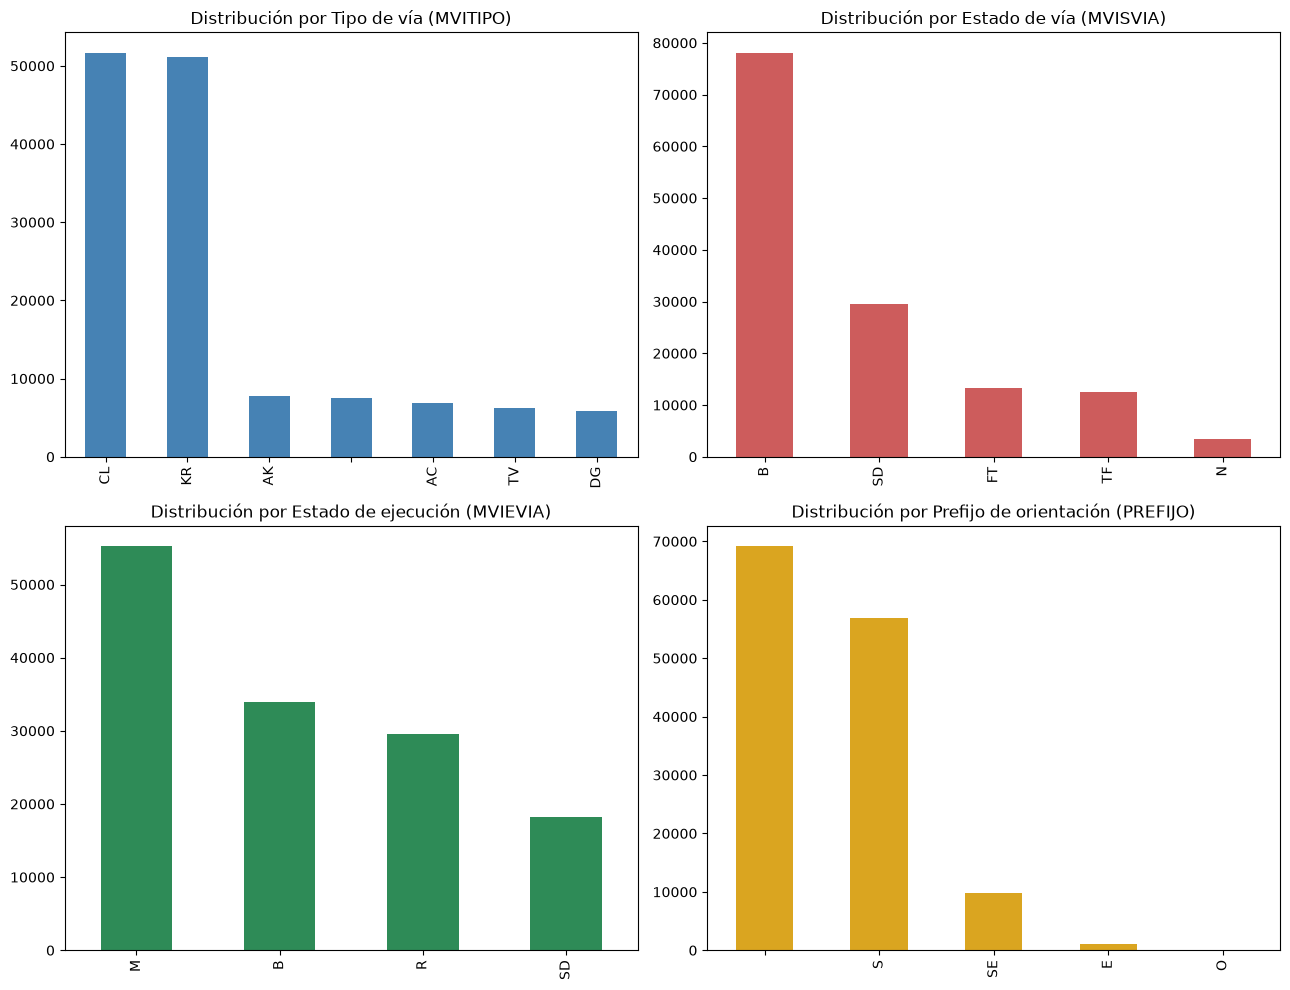

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

malla['MVITIPO'].value_counts().plot(kind='bar', ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Distribución por Tipo de vía (MVITIPO)')
axes[0,0].set_xlabel('')

malla['MVISVIA'].value_counts().plot(kind='bar', ax=axes[0,1], color='indianred')
axes[0,1].set_title('Distribución por Estado de vía (MVISVIA)')
axes[0,1].set_xlabel('')

malla['MVIEVIA'].value_counts().plot(kind='bar', ax=axes[1,0], color='seagreen')
axes[1,0].set_title('Distribución por Estado de ejecución (MVIEVIA)')
axes[1,0].set_xlabel('')

malla['PREFIJO'].value_counts(dropna=False).plot(kind='bar', ax=axes[1,1], color='goldenrod')
axes[1,1].set_title('Distribución por Prefijo de orientación (PREFIJO)')
axes[1,1].set_xlabel('')

plt.tight_layout()
plt.show()

### 3.6 Longitud de los segmentos viales

El campo original `Shape__Length` viene en grados decimales (CRS fuente `EPSG:4326`) y no es directamente interpretable como distancia. Como la capa ya está estandarizada a `EPSG:3116` (metros), se calcula una longitud real en metros a partir de la geometría reproyectada.

count    136956.000000
mean         68.484676
std          91.849683
min           0.034799
25%          31.293946
50%          50.186202
75%          83.325049
max        5035.716928
Name: longitud_m, dtype: float64


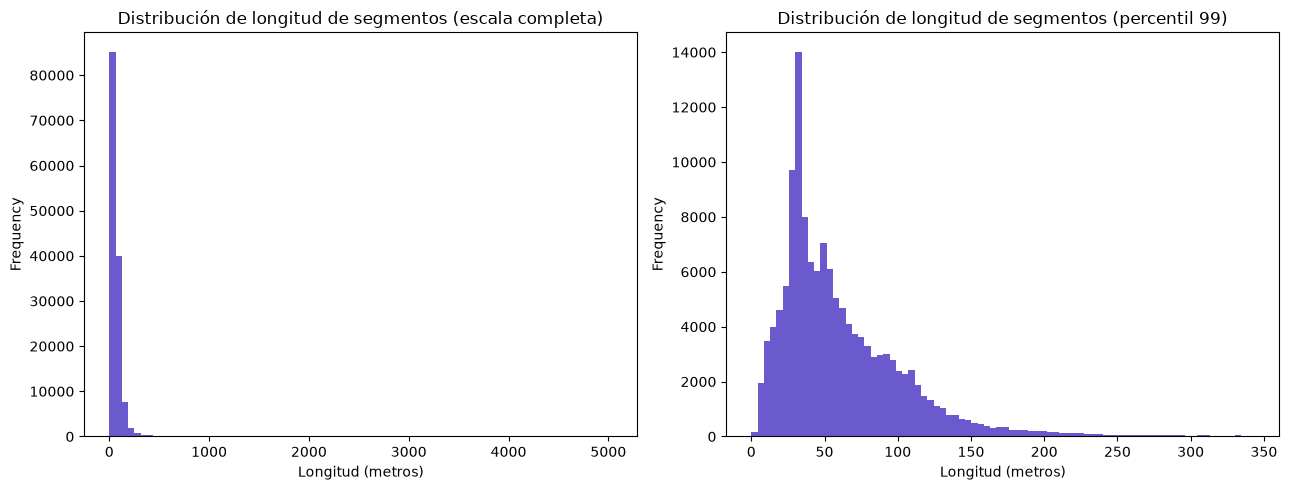

In [15]:
malla['longitud_m'] = malla.geometry.length

print(malla['longitud_m'].describe())

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
malla['longitud_m'].plot(kind='hist', bins=80, ax=ax[0], color='slateblue')
ax[0].set_title('Distribución de longitud de segmentos (escala completa)')
ax[0].set_xlabel('Longitud (metros)')

malla[malla['longitud_m'] < malla['longitud_m'].quantile(0.99)]['longitud_m'].plot(
    kind='hist', bins=80, ax=ax[1], color='slateblue')
ax[1].set_title('Distribución de longitud de segmentos (percentil 99)')
ax[1].set_xlabel('Longitud (metros)')

plt.tight_layout()
plt.show()

=== ANÁLISIS DE OUTLIERS (IQR) PARA: longitud_m ===
Q1 (Percentil 25): 31.29
Q3 (Percentil 75): 83.33
IQR: 52.03
Límite Inferior: -46.75
Límite Superior: 161.37
Total de registros analizados: 136,956 (Excluyendo nulos)
Outliers detectados: 5,988 (4.37%)
--------------------------------------------------


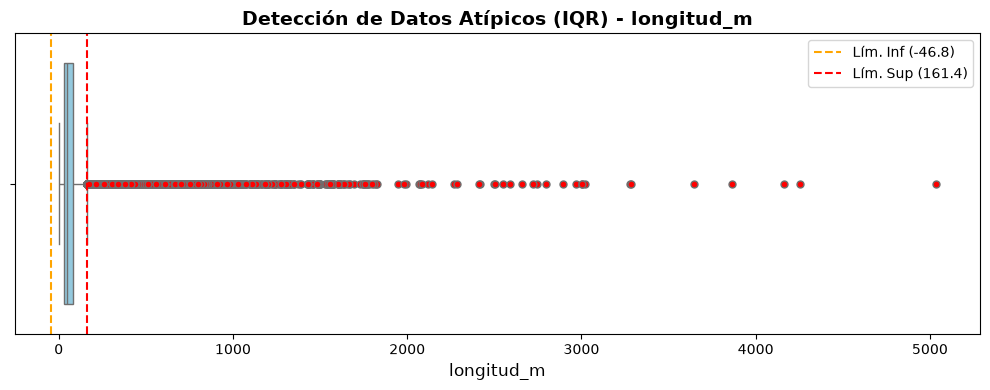

In [16]:
df_analizar = (
    malla.copy()
) 
columna_analizar = "longitud_m"  # <--- CAMBIAR

df_limpio = df_analizar.dropna(subset=[columna_analizar])

# Calcular Cuartiles e IQR
Q1 = df_limpio[columna_analizar].quantile(0.25)
Q3 = df_limpio[columna_analizar].quantile(0.75)
IQR = Q3 - Q1

# Calcular límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar outliers y datos normales
outliers = df_limpio[
    (df_limpio[columna_analizar] < limite_inferior)
    | (df_limpio[columna_analizar] > limite_superior)
]
datos_normales = df_limpio[
    (df_limpio[columna_analizar] >= limite_inferior)
    & (df_limpio[columna_analizar] <= limite_superior)
]

# Imprimir resumen analítico
print(f"=== ANÁLISIS DE OUTLIERS (IQR) PARA: {columna_analizar} ===")
print(f"Q1 (Percentil 25): {Q1:.2f}")
print(f"Q3 (Percentil 75): {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Límite Inferior: {limite_inferior:.2f}")
print(f"Límite Superior: {limite_superior:.2f}")
print(
    f"Total de registros analizados: {len(df_limpio):,} (Excluyendo nulos)"
)
print(
    f"Outliers detectados: {len(outliers):,} ({(len(outliers)/len(df_limpio))*100:.2f}%)"
)
print("-" * 50)

#Grafica
fig, ax = plt.subplots(figsize=(10, 4))

# Crear Boxplot
sns.boxplot(
    x=df_limpio[columna_analizar],
    color="skyblue",
    flierprops=dict(
        marker="o", markerfacecolor="red", markersize=5, linestyle="none"
    ),
    ax=ax,
)


ax.set_title(
    f"Detección de Datos Atípicos (IQR) - {columna_analizar}",
    fontsize=14,
    fontweight="bold",
)
ax.set_xlabel(columna_analizar, fontsize=12)

# Líneas visuales para los límites
ax.axvline(
    limite_inferior,
    color="orange",
    linestyle="--",
    linewidth=1.5,
    label=f"Lím. Inf ({limite_inferior:.1f})",
)
ax.axvline(
    limite_superior,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Lím. Sup ({limite_superior:.1f})",
)

plt.legend()
plt.tight_layout()
plt.show()

In [17]:
df_raro = malla[malla["longitud_m"] > 1000]
df_raro.head(5)

,OBJECTID,MVICCALZAD,MVICCAT,MVITIPO,MVINOMBRE,MVINALTERN,MVINPRINCI,MVINGENERA,MVINANTIGU,MVIETIQUET,MVISVIA,MVICIV,MVINVIA,MVIEVIA,MVIFRIGHT,MVITRIGHT,MVIFLEFT,MVITLEFT,MVITM,MVICM,MVINUMC,MVIACAL,MVIEFUN,MVITCONE,NAME,MUNICIPIO,PREFIJO,MVIVEL,MVIBICI,MVIRCAR,MVIESTV,MVITC,MVIRAPS,MVITSUP,MVIMONIT,MVICODIGO,CREADOR,CREADOR_DATE,EDITOR,EDITOR_DATE,MVI_VELREG,Shape__Length,geometry,longitud_m,coord_x,coord_y
291,292,159747.5,0,,,,,,,,B,50003714.0,0,SD,2.0,98.0,99.0,97.0,0,0,1,0.0,SD,5,,BOGOTA,,None,None,None,0,0,0,12,0,26601,NaN,NaT,SIGADMIN,2014-01-22 17:23:25+00:00,60,0.015077,"LINESTRING (972523.063 941517.066, 972539.748 ...",1670.167927,9.725827e+05,9.421492e+05
507,508,162914.0,0,,,,,,,,B,40001613.0,0,M,2.0,98.0,99.0,97.0,0,0,1,4.0,SD,5,,BOGOTA,,None,None,None,0,0,0,2,0,28156,NaN,NaT,SIGADMIN,2014-01-22 18:49:41+00:00,60,0.009956,"LINESTRING (995216.121 983486.315, 995080.807 ...",1102.359297,9.949450e+05,9.830513e+05
726,727,263230.0,0,,,,,,,,B,50004791.0,0,SD,2.0,98.0,99.0,97.0,0,0,1,0.0,SD,5,,BOGOTA,,None,None,None,0,0,0,12,0,24933,NaN,NaT,SIGADMIN,2014-01-22 18:18:10+00:00,60,0.009364,"LINESTRING (1000526.535 1021245.353, 1000434.1...",1037.941603,1.000077e+06,1.021505e+06
833,834,159747.5,0,,,,,,,,N,11013229.0,0,SD,2.0,98.0,99.0,97.0,0,0,2,0.0,SD,5,,BOGOTA,,None,None,None,0,0,0,12,0,14015,NaN,NaT,SIGADMIN,2014-01-22 18:13:59+00:00,60,0.011544,"LINESTRING (1000548.047 1025561.472, 1000527.5...",1278.129639,1.000095e+06,1.025269e+06
1265,1266,159747.5,19010664,DG,,,072C0000S0,027Q000000,DG 72C S,DG 72C S,B,50000291.0,0,SD,2.0,98.0,99.0,97.0,0,0,2,0.0,SD,5,72C -27Q,BOGOTA,S,None,None,None,0,0,0,12,0,27548,NaN,NaT,SIGADMIN,2014-01-22 18:52:58+00:00,60,0.010343,"LINESTRING (990336.393 994807.491, 990322.676 ...",1145.461642,9.899429e+05,9.944013e+05


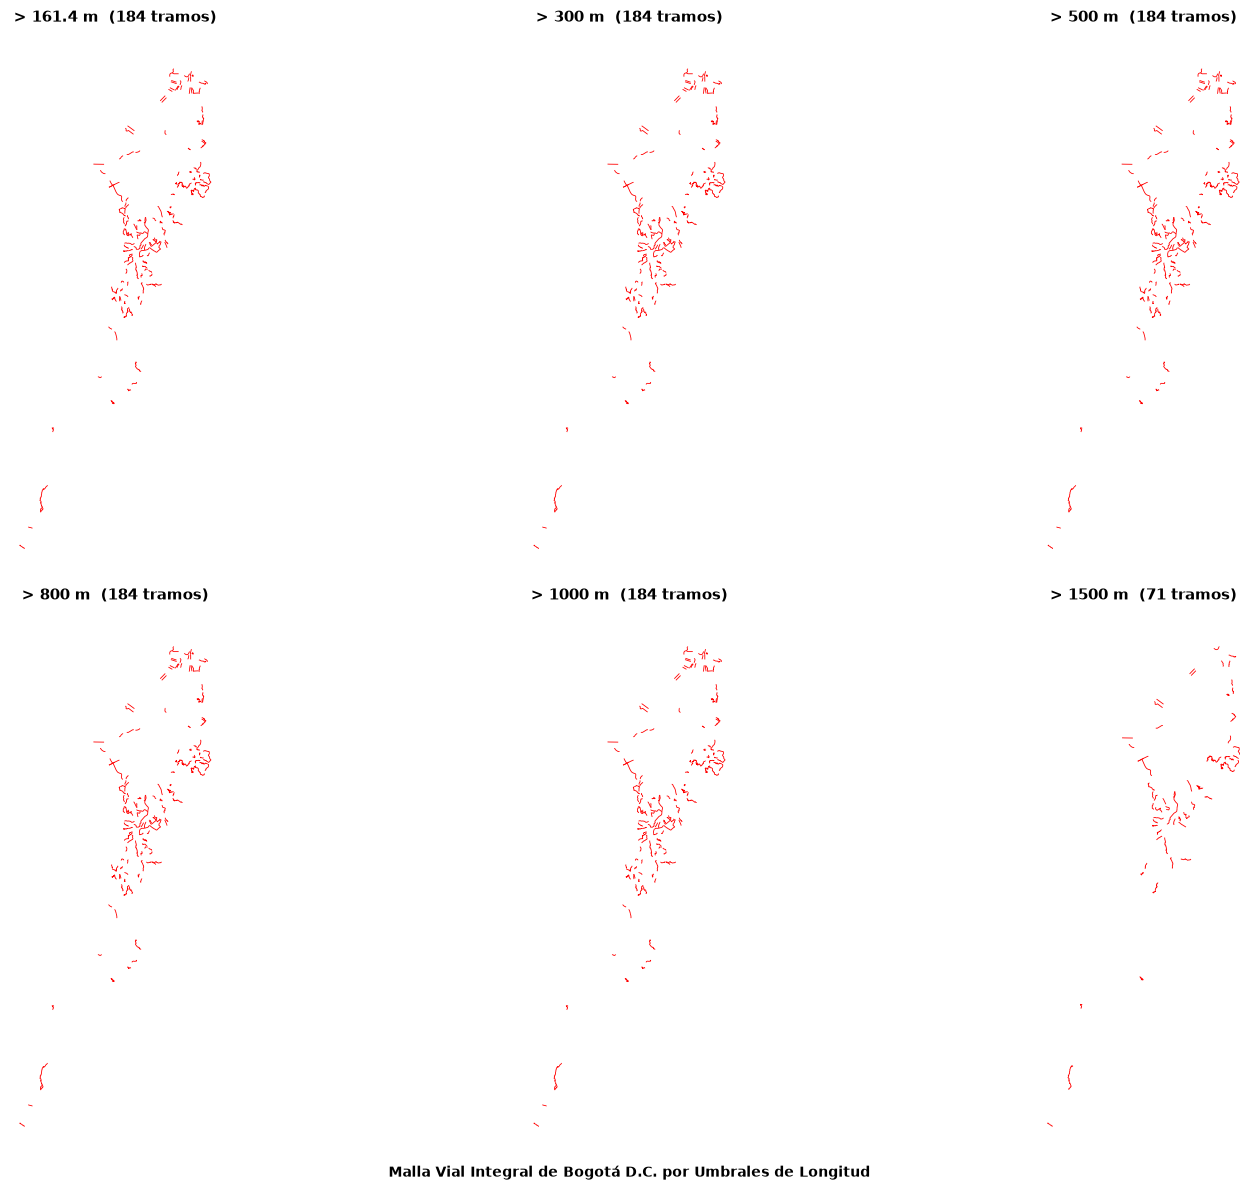

In [18]:
umbrales = [161.4, 300, 500, 800, 1000, 1500]
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
axes = axes.flatten()

for i, umbral in enumerate(umbrales):
    ax = axes[i]

    # Filtrar el GeoDataFrame
    malla_filtrada = df_raro[df_raro["longitud_m"] > umbral]

    # Graficar en el eje actual
    malla_filtrada.plot(ax=ax, linewidth=0.6, color="red")

    # Personalizar cada subgráfico
    ax.set_title(
        f"> {umbral} m  ({len(malla_filtrada):,} tramos)",
        fontsize=11,
        fontweight="bold",
    )
    ax.set_axis_off()

# Ajustar título general y espaciado
fig.suptitle(
    "Malla Vial Integral de Bogotá D.C. por Umbrales de Longitud",
    fontsize=10,
    fontweight="bold",
    y=0.0,
)
plt.tight_layout()
plt.show()

### 3.7 Geometrías nulas o inválidas

La malla vial reporta 1 registro sin geometría (`geometry: 136956 non-null` sobre 136957 filas). Se identifica explícitamente.

In [19]:
geom_nula = malla[malla.geometry.isna()]
print(f"Registros con geometría nula: {len(geom_nula)}")

geom_invalida = malla[~malla.geometry.isna() & ~malla.geometry.is_valid]
print(f"Registros con geometría inválida: {len(geom_invalida)}")

Registros con geometría nula: 1
Registros con geometría inválida: 0


### 3.8 Visualización espacial de la malla vial

La capa incluye zonas rurales muy extensas al sur (localidad de Sumapaz) que representan una fracción mínima de los segmentos (~0.3%) pero estiran la extensión del mapa y dificultan ver el detalle de la malla urbana. Se muestra primero la extensión completa y luego un recorte acotado a la zona urbana (límites en metros, `EPSG:3116`).

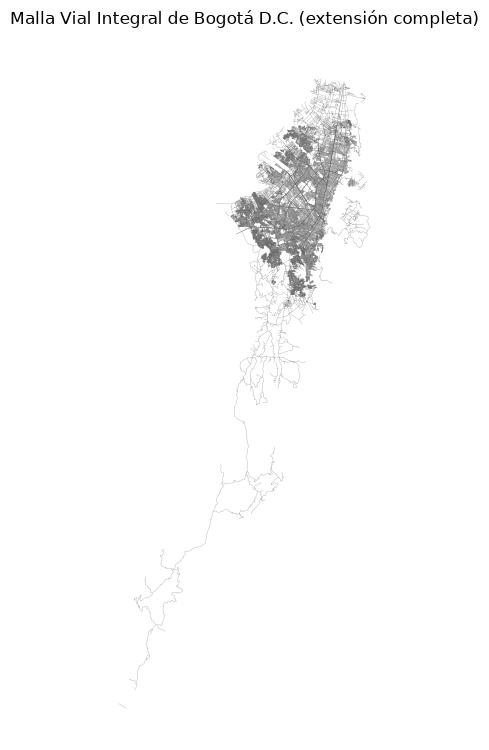

In [20]:
fig, ax = plt.subplots(figsize=(9, 9))
malla.plot(ax=ax, linewidth=0.15, color='dimgray')
ax.set_title('Malla Vial Integral de Bogotá D.C. (extensión completa)')
ax.set_axis_off()
plt.show()

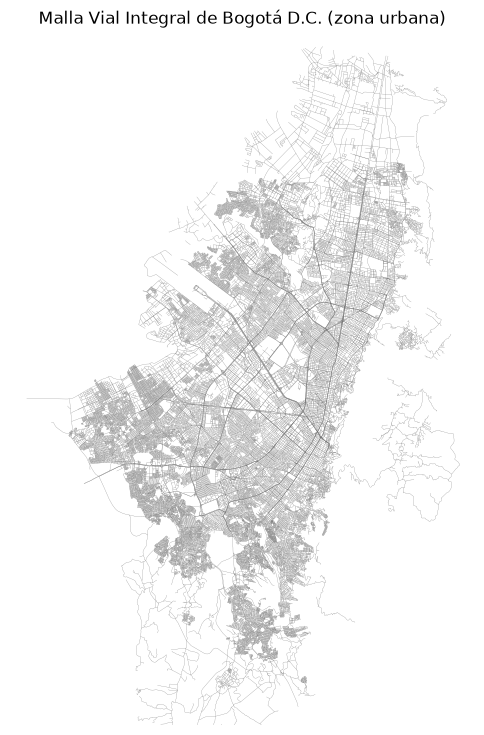

In [21]:
# Recorte visual a la zona urbana (excluye Sumapaz y bordes rurales), en metros EPSG:3116
fig, ax = plt.subplots(figsize=(9, 9))
malla.plot(ax=ax, linewidth=0.15, color='dimgray')
ax.set_xlim(981000, 1010500)
ax.set_ylim(983500, 1027500)
ax.set_title('Malla Vial Integral de Bogotá D.C. (zona urbana)')
ax.set_axis_off()
plt.show()

### 3.9 Duplicados

In [22]:
print("Registros duplicados (todas las columnas):", malla.duplicated().sum())
print("OBJECTID duplicados:", malla['OBJECTID'].duplicated().sum())
print("MVICODIGO duplicados:", malla['MVICODIGO'].duplicated().sum())

Registros duplicados (todas las columnas): 0
OBJECTID duplicados: 0
MVICODIGO duplicados: 0


In [23]:
malla['MVI_VELREG'].unique()

<IntegerArray>
[30, 60]
Length: 2, dtype: Int64

## 4. EDA — Puentes

### 4.1 Estructura general

In [24]:
print("Tipo de geometría:", puentes.geom_type.unique())
print("CRS:", puentes.crs)
puentes.info()

Tipo de geometría: <ArrowStringArray>
['MultiPolygon']
Length: 1, dtype: str
CRS: EPSG:3116
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1212 entries, 0 to 1211
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   PueCodigo     1212 non-null   int32   
 1   PueTipo       1212 non-null   int32   
 2   PueUbicaci    1212 non-null   str     
 3   SHAPE_Length  1212 non-null   float64 
 4   SHAPE_Area    1212 non-null   float64 
 5   geometry      1212 non-null   geometry
dtypes: float64(2), geometry(1), int32(2), str(1)
memory usage: 92.8 KB


### 4.2 Vista previa de los datos

In [25]:
puentes.head()

,PueCodigo,PueTipo,PueUbicaci,SHAPE_Length,SHAPE_Area,geometry
0,22156629,1,Avenida José Celestino Mutis por Avenida del C...,0.000971,4.708416e-08,"MULTIPOLYGON (((998280.597 1007762.268, 998280..."
1,24119247,1,Avenida José Celestino Mutis por Avenida del C...,0.000970,4.394591e-08,"MULTIPOLYGON (((998235.48 1007693.897, 998233...."
2,24119314,1,Avenida Jorge Uribe Botero por Avenida de los ...,0.001157,2.512141e-08,"MULTIPOLYGON (((1004041.067 1014743.721, 10040..."
3,22158560,1,Avenida Paseo Del Country por Avenida Carlos L...,0.000605,1.620756e-08,"MULTIPOLYGON (((1003223.483 1009834.876, 10032..."
4,22158594,1,Avenida Laureano Gómez por Avenida Carlos Ller...,0.000729,2.609475e-08,"MULTIPOLYGON (((1003191.943 1009797.853, 10032..."


### 4.3 Valores nulos

In [26]:
nulos_p = puentes.isna().sum()
print(nulos_p)
print("\nNo hay valores nulos en el dataset de Puentes." if nulos_p.sum() == 0 else "")

PueCodigo       0
PueTipo         0
PueUbicaci      0
SHAPE_Length    0
SHAPE_Area      0
geometry        0
dtype: int64

No hay valores nulos en el dataset de Puentes.


### 4.4 Estadística descriptiva — variables numéricas

In [27]:
puentes.describe().T

,count,mean,std,min,25%,50%,75%,max
PueCodigo,1212.0,2.342624e+07,9.572716e+05,2.214214e+07,2.216003e+07,2.411942e+07,2.412479e+07,2.419045e+07
PueTipo,1212.0,1.433993e+00,4.958286e-01,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,2.000000e+00
SHAPE_Length,1212.0,1.849275e-03,2.325624e-03,3.535513e-05,3.791207e-04,7.734528e-04,2.668110e-03,2.276622e-02
SHAPE_Area,1212.0,6.255618e-08,1.254423e-07,3.563281e-13,5.099153e-09,1.725575e-08,5.563386e-08,1.161435e-06


### 4.5 Distribución de `PueTipo` y clasificación de puentes

`PueTipo` toma 2 valores (1 y 2). El Catálogo de Objetos de IDECA define `1 = Vehicular`; el texto disponible del valor `2` está truncado, y se asume `2 = Peatonal` como **hipótesis de trabajo pendiente de verificación con IDECA/IDU**.

**Consecuencia para el análisis:** la capa completa (1.212 registros) mezcla puentes de ambos tipos. Cualquier variable llamada «puentes peatonales» debe construirse **solo con el subconjunto `PueTipo == TIPO_PEATONAL`**; contar toda la capa incluiría puentes vehiculares. La constante `TIPO_PEATONAL` se define en un único lugar (celda siguiente) para corregirla fácilmente si la verificación arrojara otro código.


PueTipo
1    686
2    526
Name: count, dtype: int64


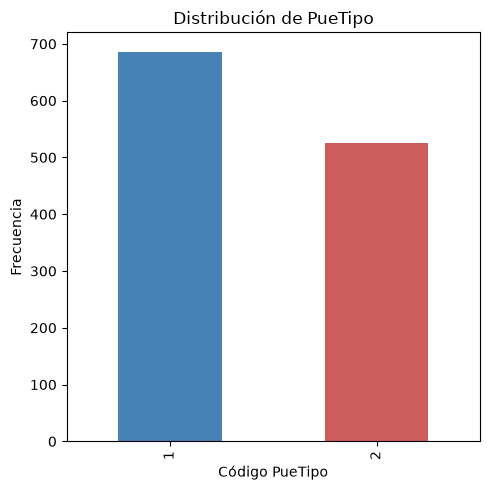

In [28]:
print(puentes['PueTipo'].value_counts())

fig, ax = plt.subplots(figsize=(5,5))
puentes['PueTipo'].value_counts().plot(kind='bar', color=['steelblue','indianred'], ax=ax)
ax.set_title('Distribución de PueTipo')
ax.set_xlabel('Código PueTipo')
ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

In [29]:
# SUPUESTO A VERIFICAR con IDECA/IDU: 1 = Vehicular (catálogo IDECA), 2 = Peatonal (por confirmar)
TIPO_VEHICULAR = 1
TIPO_PEATONAL  = 2   # <-- si la verificación indica otro código, cambiar SOLO aquí

puentes['puente_clase'] = puentes['PueTipo'].map({
    TIPO_VEHICULAR: 'vehicular',
    TIPO_PEATONAL:  'peatonal (supuesto)',
})

print(puentes['puente_clase'].value_counts(dropna=False))
assert puentes['puente_clase'].notna().all(), "Hay códigos PueTipo sin clasificar"

puentes_peatonales = puentes[puentes['PueTipo'] == TIPO_PEATONAL].copy()
puentes_vehiculares = puentes[puentes['PueTipo'] == TIPO_VEHICULAR].copy()
print(f"Peatonales (supuesto): {len(puentes_peatonales)} | Vehiculares: {len(puentes_vehiculares)}")

# Chequeo de plausibilidad: los peatonales suelen ser más pequeños que los vehiculares
puentes.assign(area_m2=puentes.geometry.area).groupby('puente_clase')['area_m2'].describe()


puente_clase
vehicular              686
peatonal (supuesto)    526
Name: count, dtype: int64
Peatonales (supuesto): 526 | Vehiculares: 686


,count,mean,std,min,25%,50%,75%,max
puente_clase,,,,,,,,
peatonal (supuesto),526.0,344.063576,407.327616,5.035062,35.563517,147.085194,573.460713,2487.461677
vehicular,686.0,1092.824205,1953.634580,0.004372,92.170858,259.578643,838.797824,14249.445753


### 4.6 Ubicaciones más frecuentes (`PueUbicaci`)

In [30]:
print("Valores únicos en PueUbicaci:", puentes['PueUbicaci'].nunique())
puentes['PueUbicaci'].value_counts().head(15)

Valores únicos en PueUbicaci: 1124


PueUbicaci
Vereda San Antonio                                                              4
Av. Boyacá con Calle 181 (costado oriental)                                     4
Avenida Centenario (Calle 17)  Con el Rio Bogotá                                3
AvJorge Eliecer(AC26) por Av C de Cali(AK86)                                    3
Río Teusaca                                                                     3
Avenida Centenario por Avenida Boyacá                                           3
Diagonal 7ABISC (costado occidental) por Transversal 73B                        3
Avenida Ciudad de Quito por Avenida Jorge Eliecer Gaitan                        3
Avenida Jose Celestino Mutis                                                    3
Avenida Fernando Mazuera por Avenida Jorge Eliécer Gaitán                       2
Avenida Ciudad de Quito por CL 63G                                              2
Avenida Ciudad de Quito por Avenida Paseo De Los Libertadores (Tercer nivel)    2
Aveni

### 4.7 Longitud y área de los puentes

Los campos originales `SHAPE_Length` y `SHAPE_Area` vienen en grados decimales (CRS fuente `EPSG:4686`). Con la capa ya estandarizada a `EPSG:3116` se calculan el perímetro y el área reales en metros.

       perimetro_m       area_m2
count  1212.000000   1212.000000
mean    204.859607    767.867034
std     257.636884   1539.046243
min       3.914938      0.004372
25%      41.993129     62.579315
50%      85.655996    211.719576
75%     295.340470    682.641250
max    2521.387858  14249.445753


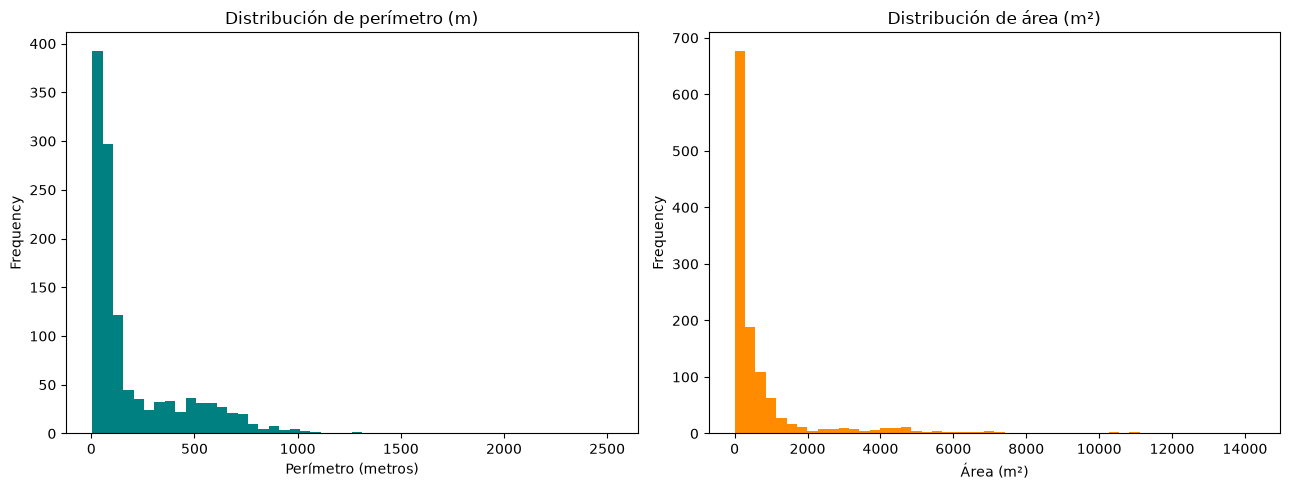

In [31]:
puentes['perimetro_m'] = puentes.geometry.length
puentes['area_m2'] = puentes.geometry.area

print(puentes[['perimetro_m', 'area_m2']].describe())

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
puentes['perimetro_m'].plot(kind='hist', bins=50, ax=ax[0], color='teal')
ax[0].set_title('Distribución de perímetro (m)')
ax[0].set_xlabel('Perímetro (metros)')

puentes['area_m2'].plot(kind='hist', bins=50, ax=ax[1], color='darkorange')
ax[1].set_title('Distribución de área (m²)')
ax[1].set_xlabel('Área (m²)')

plt.tight_layout()
plt.show()

### 4.8 Duplicados

In [32]:
print("Registros duplicados (todas las columnas):", puentes.duplicated().sum())
print("PueCodigo duplicados:", puentes['PueCodigo'].duplicated().sum())

Registros duplicados (todas las columnas): 0
PueCodigo duplicados: 0


### 4.9 Visualización espacial de los puentes

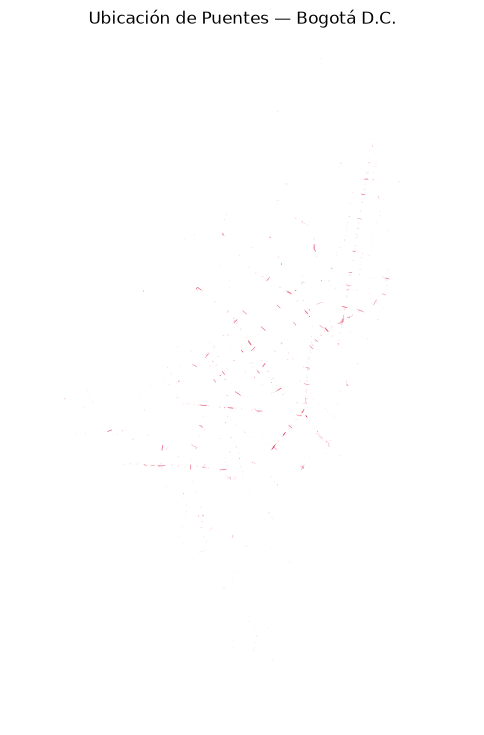

In [33]:
fig, ax = plt.subplots(figsize=(9, 9))
puentes.plot(ax=ax, color='crimson', markersize=1)
ax.set_xlim(981000, 1010500)
ax.set_ylim(983500, 1027500)
ax.set_title('Ubicación de Puentes — Bogotá D.C.')
ax.set_axis_off()
plt.show()

### 4.10 Contexto conjunto: Malla vial + Puentes

Como ambas capas ya están estandarizadas al mismo CRS (`EPSG:3116`), se pueden visualizar y cruzar directamente sin necesidad de reproyección adicional. Se muestra el mapa conjunto acotado a la zona urbana.

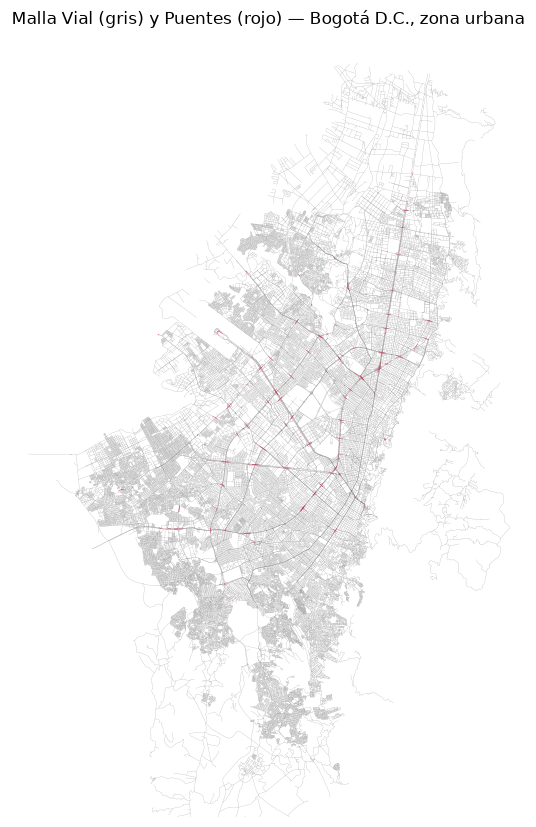

In [34]:
fig, ax = plt.subplots(figsize=(10, 10))
puentes.plot(ax=ax, color='crimson', markersize=3, zorder=2)
malla.plot(ax=ax, linewidth=0.12, color='gray', zorder=1)

ax.set_xlim(981000, 1010500)
ax.set_ylim(983500, 1027500)
ax.set_title('Malla Vial (gris) y Puentes (rojo) — Bogotá D.C., zona urbana')
ax.set_axis_off()
plt.show()

## 5. Resumen y hallazgos clave

**Estandarización de CRS**
- Ambas capas se reproyectaron a `EPSG:3116` (MAGNA-SIRGAS / Bogotá, proyectado, metros) desde sus CRS originales (`EPSG:4326` la malla vial, `EPSG:4686` los puentes). Esto permite calcular longitudes/áreas reales en metros y habilita cruces espaciales directos entre ambas capas.

**Malla Vial Integral (136.957 segmentos)**
- Geometría `LineString`/`MultiLineString`; 1 registro sin geometría. CRS estandarizado a `EPSG:3116`.
- Columnas `MVIVEL`, `MVIBICI`, `MVIRCAR` están 100% vacías y `MVIESTV`, `MVITC`, `MVIRAPS`, `MVIMONIT` son constantes en 0 — no aportan información y son candidatas a eliminarse en la fase de estandarización.
- `MVITIPO` muestra predominio de `CL` (Calle, 51.666) y `KR` (Carrera, 51.145), seguidas de `AK`, `AC`, `TV`, `DG`; 7.513 registros sin tipo asignado.
- `MVIEFUN` está informado como `SD` (Sin Dato) en prácticamente el 100% de los registros — variable no utilizable.
- Existen columnas con nulos moderados (`MVICCALZAD`, `MVINUMC`, `MVI_VELREG`, `CREADOR`) que deben tratarse antes de análisis de red.

**Puentes (1.212 registros)**
- Geometría `MultiPolygon`. CRS estandarizado a `EPSG:3116`.
- Sin valores nulos en ninguna columna.
- `PueTipo` tiene 2 categorías (686 vs. 526 registros). IDECA documenta `1 = Vehicular`; `2 = Peatonal` es un supuesto pendiente de confirmar con IDECA/IDU. La capa incluye puentes vehiculares, por lo que **el conteo de puentes peatonales debe filtrar por `PueTipo`**.
- `PueUbicaci` es texto libre con alta cardinalidad (mayoría de valores únicos), útil como referencia pero no como variable categórica directa.
- Sin registros duplicados por `PueCodigo`.


## 6. Exportar capas procesadas

Se guardan `malla` y `puentes`, ya con CRS estandarizado (`EPSG:3116`) y columnas derivadas (`longitud_m`, `perimetro_m`, `area_m2`), para que otros cuadernos (por ejemplo, el de unión de las 4 bases) las importen directamente sin repetir el procesamiento.

In [35]:
import os
os.makedirs('Data/processed', exist_ok=True)

malla.to_file('Data/processed/malla_vial_procesada.gpkg', driver='GPKG')
puentes.to_file('Data/processed/puentes_procesado.gpkg', driver='GPKG')
puentes_peatonales.to_file('Data/processed/puentes_peatonales_supuesto.gpkg', driver='GPKG')

print('Guardado: Data/processed/malla_vial_procesada.gpkg', malla.shape)
print('Guardado: Data/processed/puentes_procesado.gpkg', puentes.shape)

Guardado: Data/processed/malla_vial_procesada.gpkg (136957, 46)
Guardado: Data/processed/puentes_procesado.gpkg (1212, 9)
